Epoch 1/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 27ms/step - loss: 0.0692
Epoch 2/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - loss: 0.0407
Epoch 3/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - loss: 0.0300
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Epoch 1/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0507
Epoch 2/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0180
Epoch 3/3
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0101
Epoch 1/4
71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.7330 - loss: 1.0341 - val_accuracy: 0.8620 - val_loss: 0.5454
Epoch 2/4
71/71 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.8954 - loss: 0.4162 - val_accuracy: 0.8850 - val_loss: 0.3817
Epoch 3/4
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9188 - loss: 0.3045 - val_accuracy: 0.8960 - val_loss: 0.3353
Epoch 4/4
71/71 ━━━━━━━━━━━━━━━━━━━━ 2s 16ms/step - accuracy: 0.9323 - loss: 0.2504 - val_accuracy: 0.9070 - val_loss: 0.3000
Test Results:
63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9

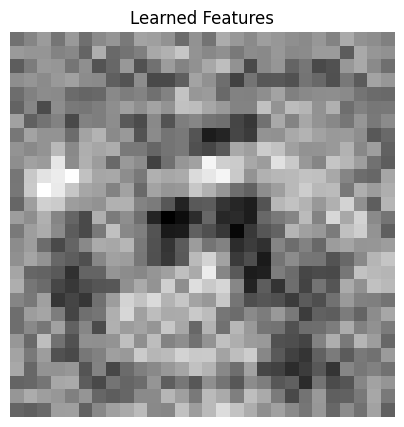

In [18]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# Load MNIST dataset
X, y = fetch_openml(
    "mnist_784", version=1,
    return_X_y=True, as_frame=False
)

X = MinMaxScaler().fit_transform(X.astype("float32"))
y = y.astype("int32")

# Split dataset
Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

Xtr, ytr = Xtr[:10000], ytr[:10000]
Xte, yte = Xte[:2000], yte[:2000]

# First Autoencoder
input1 = tf.keras.Input(shape=(784,))
hidden1 = tf.keras.layers.Dense(
    500, activation="sigmoid", name="encoder1"
)(input1)
output1 = tf.keras.layers.Dense(
    784, activation="sigmoid"
)(hidden1)

ae1 = tf.keras.Model(input1, output1)
ae1.compile(optimizer="adam", loss="mse")

ae1.fit(
    Xtr, Xtr,
    epochs=3,
    batch_size=128,
    verbose=1
)

enc1 = tf.keras.Model(input1, hidden1)
H = enc1.predict(Xtr)

# Second Autoencoder
input2 = tf.keras.Input(shape=(500,))
hidden2 = tf.keras.layers.Dense(
    250, activation="sigmoid", name="encoder2"
)(input2)
output2 = tf.keras.layers.Dense(
    500, activation="sigmoid"
)(hidden2)

ae2 = tf.keras.Model(input2, output2)
ae2.compile(optimizer="adam", loss="mse")

ae2.fit(
    H, H,
    epochs=3,
    batch_size=128,
    verbose=1
)

enc2 = tf.keras.Model(input2, hidden2)

# Classification Model
inp = tf.keras.Input(shape=(784,))
z = enc1(inp)
z = enc2(z)

out = tf.keras.layers.Dense(
    10, activation="softmax"
)(z)

model = tf.keras.Model(inp, out)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.fit(
    Xtr, ytr,
    epochs=4,
    batch_size=128,
    validation_split=0.1
)

# Test Results
print("Test Results:")
model.evaluate(Xte, yte)

# Display learned features
plt.figure(figsize=(5, 5))

plt.imshow(
    enc1.get_weights()[0][:, 0].reshape(28, 28),
    cmap="gray"
)

plt.title("Learned Features")
plt.axis("off")
plt.show()